# ShopSphere - Week 8 Model Checkpoint

**IT2226 AI Innovation & Deep Learning**

Predict whether a customer purchases in the 30 days after **2024-09-30** (October 2024).

> **Sample framing.** The dataset is a sample of the customer base, not a full census.
> Results describe segment-level tendencies and are not used to make decisions about
> individual customers. No customer IDs appear in this notebook.

| Item | Value |
|---|---|
| Modelling grain | one row per sampled customer |
| Train / validation / test | 64,000 / 12,800 / 16,000 |
| Target rate (train) | 14.6% |
| Selected model | Ensemble (Deep MLP + Gradient Boosting) |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, precision_recall_curve, roc_curve,
                             roc_auc_score)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

BASE = Path.cwd()
if not (BASE / "artifacts").exists():
    BASE = BASE / "ShopSphere"
REPORTS = BASE / "artifacts" / "reports" / "fixed"
FEAT = BASE / "artifacts" / "features"
DATA = BASE / "data" / "clean"

metrics = json.loads((REPORTS / "metrics.json").read_text(encoding="utf-8"))
comp = pd.read_csv(REPORTS / "model_comparison.csv").sort_values("pr_auc", ascending=False)
val = pd.read_csv(REPORTS / "validation_predictions.csv")
SEL, THR = metrics["selected_model"], metrics["selected_threshold"]

print(f"Selected model : {SEL}")
print(f"Threshold      : {THR:.3f}")
print(f"Split          : {metrics['split']}")
print(f"Test positives : {metrics['submission_positives']:,} ({metrics['submission_positive_rate']:.1%})")

Selected model : Ensemble (MLP + HGB)
Threshold      : 0.707
Split          : {'train': 51200, 'validation': 12800, 'test': 16000}
Test positives : 2,651 (16.6%)


## 1. Data and leakage control

All features are built from data on or before the 2024-09-30 cutoff. The 64,000 train and
16,000 test rows are disjoint samples, and the target is purchases in the following 30-day
window, so there is no target leakage. Thirteen cleaned source tables feed 180 customer-level
features (174 numeric, 6 categorical); the inventory below also includes the train and test
label files.

In [2]:
rows = []
for p in sorted(DATA.glob("*.csv")):
    if p.name == "sample_submission.csv":
        continue
    with open(p, encoding="utf-8", errors="ignore") as fh:
        rows.append({"table": p.stem, "rows": sum(1 for _ in fh) - 1})
inventory = pd.DataFrame(rows)
display(inventory)
print("total rows:", f"{inventory['rows'].sum():,}", "| tables:", len(inventory))

,table,rows
0,campaign_daily_performance,11867
1,customer_preferences,80000
2,customers,80000
3,deliveries,301243
4,geo_data,100
5,marketing_campaigns,245
6,offer_catalogue,7
7,products,400
8,retention_budget_2024Q4,65
9,retention_contact_history,9000


total rows: 2,813,499 | tables: 16


## 2. Model comparison (held-out 12,800 sample customers)

Two non-deep-learning baselines (logistic regression, gradient boosting), a PyTorch MLP
averaged over three seeds, and two blended ensembles. PR-AUC is the primary metric because
only 14.6% of sampled customers purchase.

In [3]:
display(comp.set_index("model")[["pr_auc", "roc_auc", "f1", "precision", "recall",
                                 "threshold", "brier"]].round(4))

,pr_auc,roc_auc,f1,precision,recall,threshold,brier
model,,,,,,,
Ensemble (MLP + HGB),0.5767,0.8758,0.5493,0.5096,0.5957,0.7067,0.1478
Ensemble (MLP + HGB + LogReg),0.5764,0.8756,0.5468,0.4715,0.6509,0.6644,0.1490
Gradient Boosting (baseline),0.5747,0.8759,0.5472,0.4882,0.6225,0.6765,0.1443
Deep Learning MLP (seed ensemble),0.5712,0.8715,0.5465,0.4845,0.6268,0.6963,0.1546
Logistic Regression (baseline),0.5689,0.8717,0.5391,0.4901,0.5989,0.6999,0.1536
Dummy (prior),0.1457,0.5000,0.2544,0.1457,1.0000,0.1457,0.1245


### Interpretation

- The blended **MLP + HGB** ensemble has the best PR-AUC and F1, so it is selected.
- The MLP alone has the best F1 at its own threshold and is close on PR-AUC; blending with
  gradient boosting improves ranking stability.
- The dummy prior (PR-AUC 0.146) shows the lift from behavioural features.

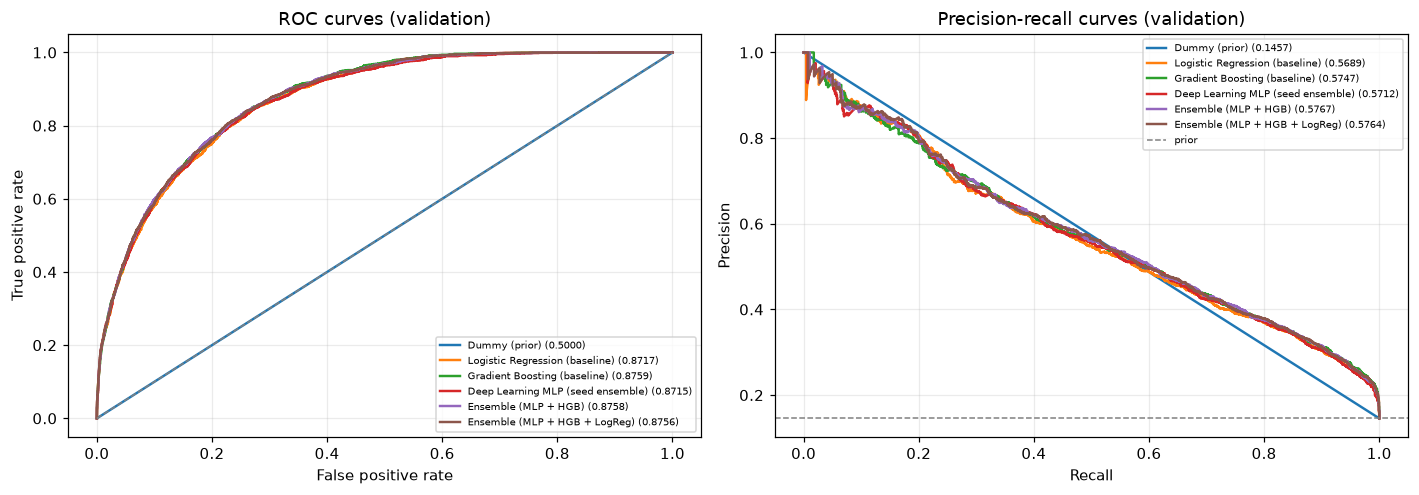

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
model_cols = [c for c in val.columns if c not in ("customer_id", "target")]
for i, name in enumerate(model_cols):
    fpr, tpr, _ = roc_curve(val["target"], val[name])
    axes[0].plot(fpr, tpr, lw=1.6, color=colors[i],
                 label=f"{name} ({roc_auc_score(val['target'], val[name]):.4f})")
    prec, rec, _ = precision_recall_curve(val["target"], val[name])
    axes[1].plot(rec, prec, lw=1.6, color=colors[i],
                 label=f"{name} ({average_precision_score(val['target'], val[name]):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
axes[0].set(title="ROC curves (validation)", xlabel="False positive rate",
            ylabel="True positive rate")
axes[1].axhline(val["target"].mean(), ls="--", color="grey", lw=1, label="prior")
axes[1].set(title="Precision-recall curves (validation)", xlabel="Recall",
            ylabel="Precision")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=6.5, loc="best")
plt.tight_layout()
plt.show()

,metric,value
0,precision,0.5094
1,recall,0.5952
2,f1,0.5490
3,accuracy,0.8575
4,flagged,0.1702
5,tp,1110.0000
6,fp,1069.0000
7,fn,755.0000
8,tn,9866.0000


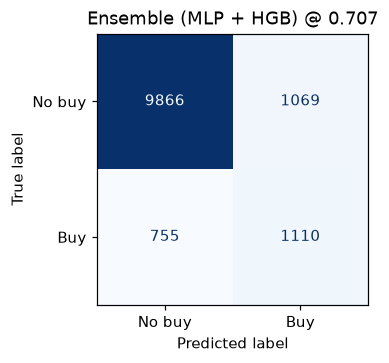

In [5]:
prob = val[SEL].to_numpy()
y = val["target"].to_numpy()
pred = (prob >= THR).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
out = pd.DataFrame({
    "metric": ["precision", "recall", "f1", "accuracy", "flagged", "tp", "fp", "fn", "tn"],
    "value": [tp / max(tp + fp, 1), tp / max(tp + fn, 1),
              2 * tp / max(2 * tp + fp + fn, 1), (tp + tn) / len(y), pred.mean(),
              tp, fp, fn, tn],
})
display(out.round(4))

fig, ax = plt.subplots(figsize=(4, 3.2))
ConfusionMatrixDisplay(np.array([[tn, fp], [fn, tp]]),
                       display_labels=["No buy", "Buy"]).plot(
    ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"{SEL} @ {THR:.3f}")
plt.show()

## 3. Deep-learning model

A 256-128-64 MLP with batch norm, dropout, class-weighted BCE, AdamW and early stopping,
averaged over three seeds. The chart shows validation PR-AUC per epoch; early stopping
restored each seed's best epoch.

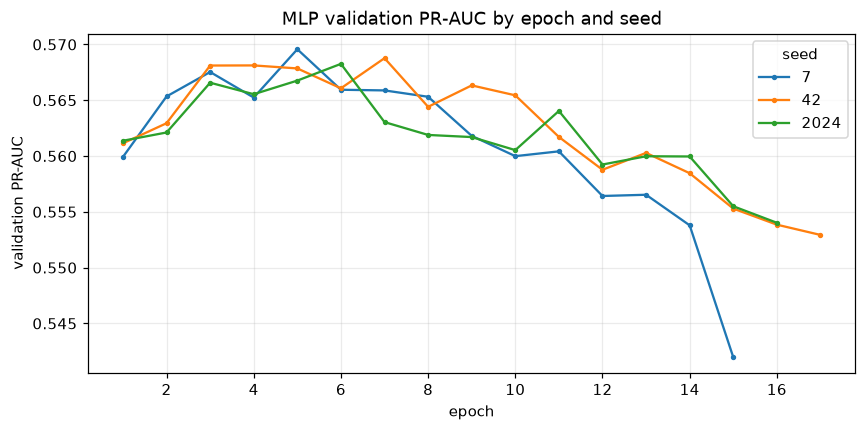

In [6]:
log = pd.read_csv(REPORTS / "mlp_training_log.csv")
pivot = log.pivot_table(index="epoch", columns="seed", values="val_ap")
pivot.plot(figsize=(9, 4), marker="o", ms=2.5)
plt.title("MLP validation PR-AUC by epoch and seed")
plt.xlabel("epoch")
plt.ylabel("validation PR-AUC")
plt.grid(alpha=0.25)
plt.legend(title="seed")
plt.show()

## 4. Feature importance

Permutation importance on the gradient-boosting model (drop in validation PR-AUC when a
transformed feature is shuffled). Behavioural recency and frequency dominate, which matches
the retention domain.

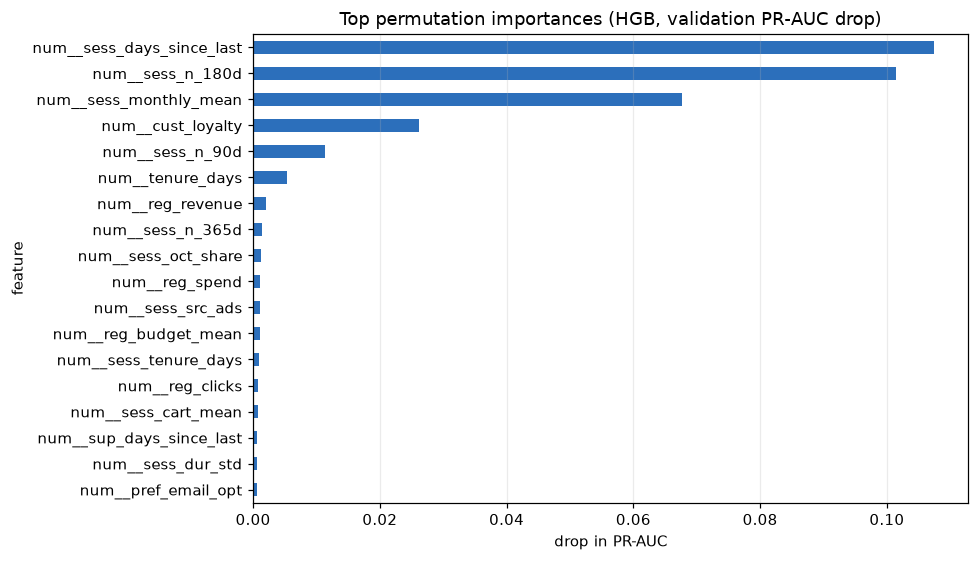

In [7]:
imp = pd.read_csv(REPORTS / "feature_importance_hgb.csv").head(18).iloc[::-1]
imp.plot.barh(x="feature", y="importance", figsize=(9, 5.2), legend=False, color="#2c6fbb")
plt.title("Top permutation importances (HGB, validation PR-AUC drop)")
plt.xlabel("drop in PR-AUC")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Segment and fairness analysis

Because the data is a sample, analysis is done at segment level. The tier snapshot shows how
a large low-propensity group (Bronze) differs from a small high-propensity group (Platinum).
The multi-group table then intersects conditions - for example Bronze AND active AND high
session volume, or email opt-in AND high sessions - so we can see which combinations carry
the expected buyers.

Tier snapshot (test sample)


,customers,mean_propensity,expected_buyers,flag_rate,share_expected
cust_tier,,,,,
Bronze,10198,0.179,1824.853,0.020,0.339
Silver,2830,0.502,1419.378,0.199,0.263
Gold,1670,0.659,1099.827,0.519,0.204
Platinum,1302,0.801,1043.335,0.783,0.194


Country snapshot (test sample)


,customers,mean_propensity,expected_buyers,flag_rate,share_expected
cust_country,,,,,
US,6397,0.342,2184.653,0.171,0.406
UK,3188,0.344,1097.137,0.171,0.204
DE,3159,0.338,1068.759,0.161,0.198
FR,1626,0.321,521.319,0.151,0.097
IN,1630,0.316,515.525,0.156,0.096



Multi-group intersections (test sample)


,segment,customers,mean_propensity,expected_buyers,share_expected,flag_rate
1,Email opt-in + high sessions,3132,0.753,2359.152,0.438,0.654
2,Bronze + email opt-in,6377,0.198,1259.565,0.234,0.025
3,High loyalty + cooling,548,0.603,330.604,0.061,0.254
4,Gold/Silver + recent complaint,221,0.661,146.063,0.027,0.462
0,Bronze + active + high sessions,197,0.654,128.761,0.024,0.345
8,DNC customers,360,0.315,113.430,0.021,0.172
7,Open complaint (all tiers),70,0.431,30.194,0.006,0.271
5,High spend + dormant,62,0.300,18.581,0.003,0.000
6,Platinum + dormant,42,0.289,12.117,0.002,0.000


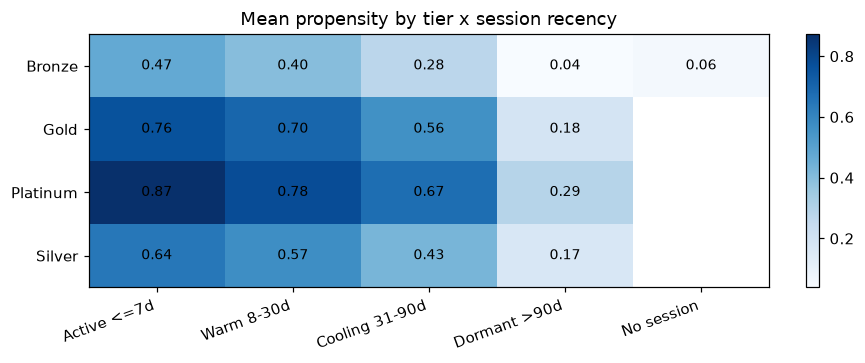


Selection rate by cust_country


,customers,flagged,selection_rate
cust_country,,,
UK,3188,546,0.171
US,6397,1094,0.171
DE,3159,510,0.161
IN,1630,255,0.156
FR,1626,246,0.151



Selection rate by cust_tier


,customers,flagged,selection_rate
cust_tier,,,
Platinum,1302,1019,0.783
Gold,1670,867,0.519
Silver,2830,563,0.199
Bronze,10198,202,0.020



DNC customers excluded from outreach by policy: 360
Customers with open complaints: 70


In [8]:
test = pd.read_pickle(FEAT / "test_features.pkl")
probs = pd.read_csv(REPORTS / "test_probabilities.csv")
tv = probs[["customer_id", "selected_probability"]].merge(
    test[["customer_id", "cust_country", "cust_tier", "pref_email_opt", "pref_dnc",
          "sup_open_n", "sup_recent_complaint", "sup_n", "cust_loyalty", "tenure_days",
          "sess_n_180d", "sess_days_since_last", "txn_spend_180d", "txn_days_since_last"]],
    on="customer_id")
tv["flagged"] = tv["selected_probability"] >= THR
tv["recency_band"] = np.select(
    [tv["sess_days_since_last"].isna(), tv["sess_days_since_last"] <= 7,
     tv["sess_days_since_last"] <= 30, tv["sess_days_since_last"] <= 90],
    ["No session", "Active <=7d", "Warm 8-30d", "Cooling 31-90d"], default="Dormant >90d")
tv["loyalty_band"] = pd.qcut(tv["cust_loyalty"].rank(method="first"), 4,
                             labels=["Q1 low", "Q2", "Q3", "Q4 high"])
tv["session_band"] = pd.qcut(tv["sess_n_180d"].rank(method="first"), 4,
                             labels=["Q1 low", "Q2", "Q3", "Q4 high"])
tv["spend_band"] = pd.qcut(tv["txn_spend_180d"].rank(method="first"), 4,
                           labels=["Q1 low", "Q2", "Q3", "Q4 high"])


def summarize(frame, by):
    g = frame.groupby(by, observed=True).agg(
        customers=("selected_probability", "size"),
        mean_propensity=("selected_probability", "mean"),
        expected_buyers=("selected_probability", "sum"),
        flag_rate=("selected_probability", lambda s: (s >= THR).mean()))
    g["share_expected"] = g["expected_buyers"] / frame["selected_probability"].sum()
    return g.sort_values("expected_buyers", ascending=False)


print("Tier snapshot (test sample)")
display(summarize(tv, "cust_tier").round(3))
print("Country snapshot (test sample)")
display(summarize(tv, "cust_country").round(3))

segments = {
    "Bronze + active + high sessions": (tv["cust_tier"] == "Bronze") & (tv["recency_band"] == "Active <=7d") & (tv["session_band"] == "Q4 high"),
    "Email opt-in + high sessions": (tv["pref_email_opt"] == 1) & (tv["session_band"] == "Q4 high"),
    "Bronze + email opt-in": (tv["cust_tier"] == "Bronze") & (tv["pref_email_opt"] == 1),
    "High loyalty + cooling": (tv["loyalty_band"] == "Q4 high") & (tv["recency_band"] == "Cooling 31-90d"),
    "Gold/Silver + recent complaint": tv["cust_tier"].isin(["Gold", "Silver"]) & (tv["sup_recent_complaint"] == 1),
    "High spend + dormant": (tv["spend_band"] == "Q4 high") & (tv["recency_band"] == "Dormant >90d"),
    "Platinum + dormant": (tv["cust_tier"] == "Platinum") & (tv["recency_band"] == "Dormant >90d"),
    "Open complaint (all tiers)": tv["sup_open_n"].fillna(0) > 0,
    "DNC customers": tv["pref_dnc"] == 1,
}
rows = []
total = tv["selected_probability"].sum()
for name, mask in segments.items():
    s = tv.loc[mask, "selected_probability"]
    rows.append({"segment": name, "customers": len(s), "mean_propensity": s.mean(),
                 "expected_buyers": s.sum(), "share_expected": s.sum() / total,
                 "flag_rate": (s >= THR).mean() if len(s) else np.nan})
print("\nMulti-group intersections (test sample)")
display(pd.DataFrame(rows).sort_values("expected_buyers", ascending=False).round(3))

pivot = tv.pivot_table(index="cust_tier", columns="recency_band",
                       values="selected_probability", aggfunc="mean")
pivot = pivot.reindex(columns=[c for c in ["Active <=7d", "Warm 8-30d", "Cooling 31-90d",
                                          "Dormant >90d", "No session"] if c in pivot.columns])
fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(pivot.to_numpy(dtype=float), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=20, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Mean propensity by tier x session recency")
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()

for key in ["cust_country", "cust_tier"]:
    table = (tv.groupby(key).agg(customers=("flagged", "size"),
                                 flagged=("flagged", "sum"))
             .assign(selection_rate=lambda d: d["flagged"] / d["customers"])
             .sort_values("selection_rate", ascending=False))
    print(f"\nSelection rate by {key}")
    display(table.round(3))
print("\nDNC customers excluded from outreach by policy:", int((tv["pref_dnc"] == 1).sum()))
print("Customers with open complaints:", int((tv["sup_open_n"].fillna(0) > 0).sum()))

## 6. First test submission

The submission flags the top-scoring rows of the test sample at the tuned threshold. The top
decile carries most of the expected purchases, so outreach can be prioritised by segment.

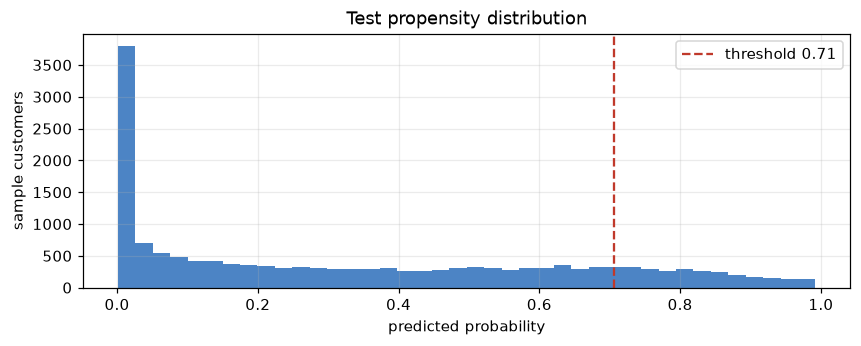

flagged 2,651 of 16,000 (16.6%)
top-decile share of expected purchases: 26.1%
count    16000.0000
mean         0.3367
std          0.3042
min          0.0013
25%          0.0313
50%          0.2661
75%          0.6040
max          0.9923
Name: selected_probability, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(probs["selected_probability"], bins=40, color="#2c6fbb", alpha=0.85)
ax.axvline(THR, color="#c0392b", ls="--", label=f"threshold {THR:.2f}")
ax.set(xlabel="predicted probability", ylabel="sample customers",
       title="Test propensity distribution")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

flagged = (probs["selected_probability"] >= THR).astype(int)
top_decile = probs["selected_probability"] >= probs["selected_probability"].quantile(0.9)
share = (probs.loc[top_decile, "selected_probability"].sum()
         / probs["selected_probability"].sum())
print(f"flagged {flagged.sum():,} of {len(flagged):,} ({flagged.mean():.1%})")
print(f"top-decile share of expected purchases: {share:.1%}")
print(probs["selected_probability"].describe().round(4))

## 7. Agentic win-back preview (segment policy layer)

The agent will call this policy tool. It filters rows by consent/DNC, open complaints and
recent contact, assigns an offer by tier and caps spend by the weekly per-country budget.
The output is aggregated to segments so no individual customer record is exposed.

In [10]:
offers = pd.read_csv(DATA / "offer_catalogue.csv")
budget = pd.read_csv(DATA / "retention_budget_2024Q4.csv")
plan_src = tv.merge(test[["customer_id", "pref_channel", "ret_days_since_last"]],
                    on="customer_id").drop(columns=["customer_id"])
cand = plan_src[(plan_src["selected_probability"] >= THR)
                & (plan_src["pref_dnc"] == 0)
                & (plan_src["sup_open_n"].fillna(0) == 0)].copy()
cand = cand[cand["ret_days_since_last"].isna() | (cand["ret_days_since_last"] >= 14)].copy()


def tier_offer(r):
    if r["sup_recent_complaint"] == 1:
        return "OFF-SRC"
    return {"Platinum": "OFF-V20", "Gold": "OFF-V15",
            "Silver": "OFF-V15"}.get(r["cust_tier"], "OFF-FS")


cand["offer"] = cand.apply(tier_offer, axis=1)
AOV = 80.0


def cost(code):
    rec = offers.loc[offers["offer_code"] == code].iloc[0]
    return rec["value"] * AOV if rec["offer_type"] == "Voucher" else rec["value"]


cand["cost"] = cand["offer"].map(cost)
week = budget["week_start"].min()
caps = budget[budget["week_start"] == week].set_index("country")["retention_budget_usd"]

pick = []
for country, g in cand.sort_values("selected_probability", ascending=False).groupby("cust_country"):
    spent = 0.0
    for _, r in g.iterrows():
        if spent + r["cost"] > caps.get(country, 0):
            break
        pick.append(r)
        spent += r["cost"]
plan = pd.DataFrame(pick).sort_values("selected_probability", ascending=False)
print(f"week {week}: {len(cand):,} eligible -> {len(plan):,} contacts, "
      f"expected buyers {plan['selected_probability'].sum():.0f}, "
      f"spend ${plan['cost'].sum():,.0f}")

plan_agg = (plan.groupby(["cust_country", "cust_tier", "offer", "pref_channel"])
            .agg(contacts=("selected_probability", "size"),
                 expected_buyers=("selected_probability", "sum"),
                 estimated_spend=("cost", "sum"))
            .reset_index().sort_values("expected_buyers", ascending=False))
print("\nSegment-level plan (no customer IDs)")
display(plan_agg.round({"expected_buyers": 1, "estimated_spend": 2}).head(20))

print("\nOffer mix by tier")
display(plan.groupby(["cust_tier", "offer"])
        .agg(contacts=("selected_probability", "size"),
             expected_buyers=("selected_probability", "sum"),
             spend=("cost", "sum")).round({"expected_buyers": 1, "spend": 2}))

week 2024-10-07: 2,496 eligible -> 2,292 contacts, expected buyers 1917, spend $29,426

Segment-level plan (no customer IDs)


,cust_country,cust_tier,offer,pref_channel,contacts,expected_buyers,estimated_spend
118,US,Platinum,OFF-V20,email,183,159.5,2928.0
110,US,Gold,OFF-V15,email,145,119.7,1740.0
91,UK,Platinum,OFF-V20,email,83,72.8,1328.0
125,US,Silver,OFF-V15,email,89,70.7,1068.0
117,US,Platinum,OFF-V20,app_push,81,69.3,1296.0
17,DE,Platinum,OFF-V20,email,76,65.7,1216.0
9,DE,Gold,OFF-V15,email,78,63.4,936.0
83,UK,Gold,OFF-V15,email,73,60.1,876.0
109,US,Gold,OFF-V15,app_push,65,53.2,780.0
16,DE,Platinum,OFF-V20,app_push,45,38.6,720.0



Offer mix by tier


contacts  expected_buyers    spend
cust_tier offer                                      
Bronze    OFF-FS        144            112.3    864.0
          OFF-SRC         4              3.2     40.0
Gold      OFF-SRC        61             51.4    610.0
          OFF-V15       697            571.7   8364.0
Platinum  OFF-SRC       124            113.5   1240.0
          OFF-V20       804            701.8  12864.0
Silver    OFF-SRC        26             21.5    260.0
          OFF-V15       432            341.6   5184.0

## 8. Limitations and next steps

- **Sample, not census:** estimates describe segment tendencies; widen or reweight the
  sample before making population claims.
- **Causal vs predictive:** propensity is not uplift; run a randomised segment holdout
  before scaling incentives.
- **Temporal drift:** validate on the next 30-day window and monitor calibration monthly.
- **Deep model:** seed ensembling helped slightly; try categorical embeddings next.
- **Agent:** wrap the planner as a tool, add an LLM reasoner for offer explanation and a
  human approval step for high-value segments.
- **Deliverables:** this notebook, `artifacts/reports/fixed/Week8_model_report.md`,
  `app/app.py` (interactive dashboard) and `artifacts/outputs/submission.csv`.